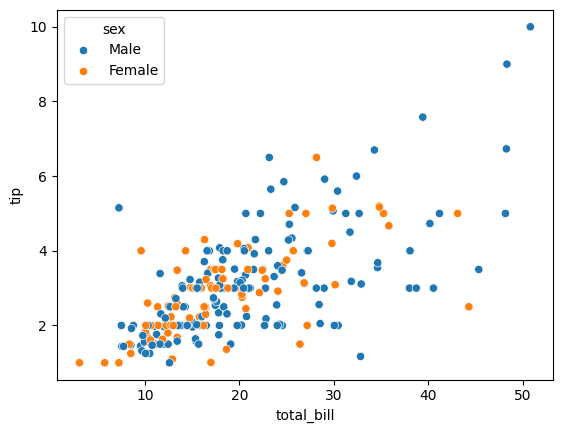

In [1]:
import seaborn as sns

# Seaborn is a Python data visualization library built on top of Matplotlib.
# It is designed for statistical plotting and makes it easy to create
# attractive charts such as scatter plots, box plots, bar plots, violin plots,
# heatmaps, and pair plots.
#
# It is commonly used with Pandas for exploratory data analysis (EDA)
# and for visualizing relationships in datasets.
#
# Example:
import matplotlib.pyplot as plt

tips = sns.load_dataset("tips")
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="sex")
plt.show()

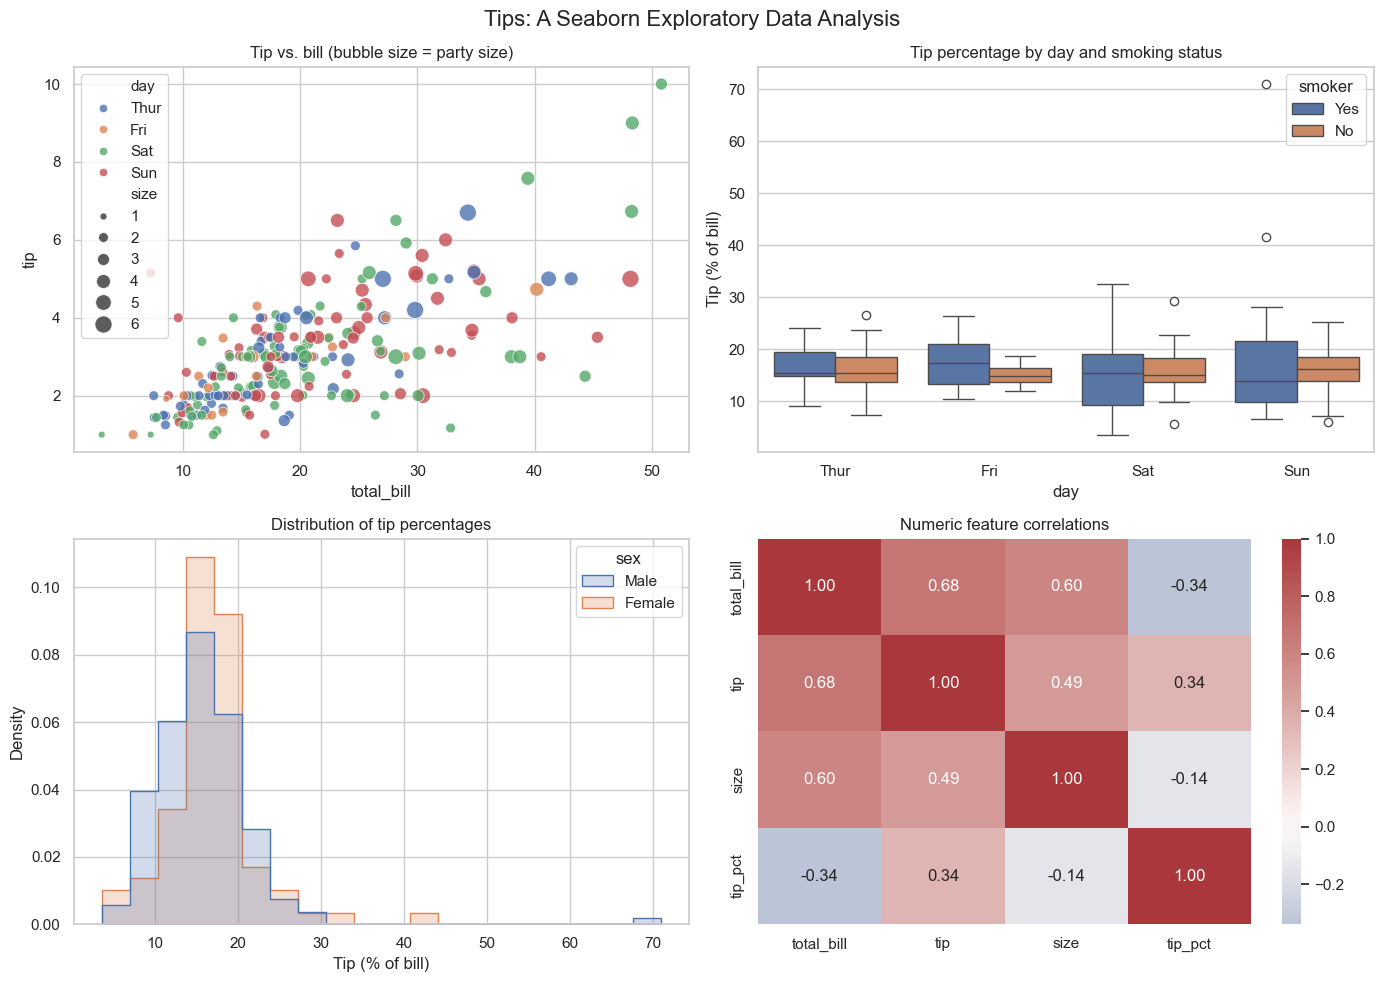

Average tip percentage by day:


day
Thur    16.1
Fri     17.0
Sat     15.3
Sun     16.7
Name: tip_pct, dtype: float64

In [2]:
# Explore what influences tipping: bill size, day, smoking status, and party size
tips_project = tips.copy()
tips_project["tip_pct"] = 100 * tips_project["tip"] / tips_project["total_bill"]

sns.set_theme(style="whitegrid", palette="deep")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.scatterplot(
    data=tips_project, x="total_bill", y="tip",
    hue="day", size="size", sizes=(25, 150), alpha=0.8, ax=axes[0, 0]
)
axes[0, 0].set_title("Tip vs. bill (bubble size = party size)")

sns.boxplot(
    data=tips_project, x="day", y="tip_pct", hue="smoker", ax=axes[0, 1]
)
axes[0, 1].set_title("Tip percentage by day and smoking status")
axes[0, 1].set_ylabel("Tip (% of bill)")

sns.histplot(
    data=tips_project, x="tip_pct", hue="sex",
    bins=20, element="step", stat="density", common_norm=False, ax=axes[1, 0]
)
axes[1, 0].set_title("Distribution of tip percentages")
axes[1, 0].set_xlabel("Tip (% of bill)")

corr = tips_project[["total_bill", "tip", "size", "tip_pct"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[1, 1])
axes[1, 1].set_title("Numeric feature correlations")

fig.suptitle("Tips: A Seaborn Exploratory Data Analysis", fontsize=16)
plt.tight_layout()
plt.show()

print("Average tip percentage by day:")
display(tips_project.groupby("day", observed=True)["tip_pct"].mean().round(1))